In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data

x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data")

In [2]:
print("Training data:", x_train.shape)
print("Test data:", x_test.shape)
print("Labels:", y_train.shape)

Training data: (328135, 321)
Test data: (109379, 321)
Labels: (328135,)


Class -1: 299160 (91.17%)
Class 1: 28975 (8.83%)


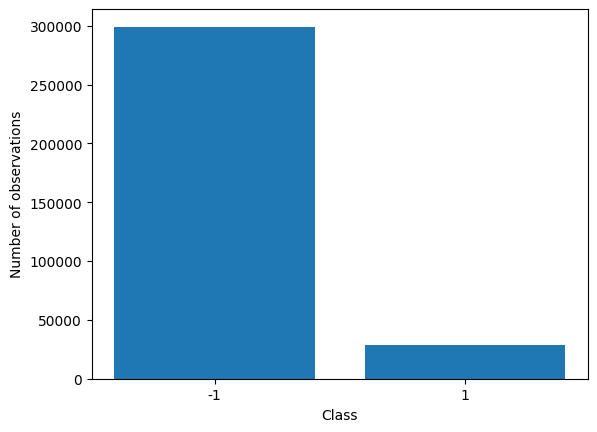

In [3]:
labels, counts = np.unique(y_train, return_counts=True)

for label, count in zip(labels, counts):
    print(f"Class {label}: {count} ({count / len(y_train):.2%})")

plt.bar(labels.astype(str), counts)
plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.show()

In [4]:
missing_ratio = np.mean(np.isnan(x_train), axis=0)

print("Total NaN values:", np.isnan(x_train).sum())
print("Columns containing NaN:", np.sum(missing_ratio > 0))
print("Columns with more than 50% NaN:", np.sum(missing_ratio > 0.5))

Total NaN values: 47175779
Columns containing NaN: 239
Columns with more than 50% NaN: 147


In [5]:
# Identify empty and constant columns.
empty_columns = np.all(np.isnan(x_train), axis=0)

constant_columns = np.zeros(x_train.shape[1], dtype=bool)

for j in range(x_train.shape[1]):
    values = x_train[:, j]
    values = values[~np.isnan(values)]
    constant_columns[j] = len(values) > 0 and np.all(values == values[0])

print("Entirely empty columns:", empty_columns.sum())
print("Constant non-empty columns:", constant_columns.sum())

Entirely empty columns: 0
Constant non-empty columns: 6
